Sample langgraph example

In [ ]:
#creating a programmin assistant, chaining workflows

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
Weather_API_Key = os.getenv("WEATHER_API_KEY")


In [2]:
from langchain.chat_models import init_chat_model

llm_groq_1 = init_chat_model(
    model="openai/gpt-oss-120b", 
    model_provider="groq",
    metadata={
        "ls_provider": "groq", 
        "ls_model_name": "openai/gpt-oss-120b"
    }
)
llm_groq_2 = init_chat_model(
    model="qwen/qwen3.8-27b", 
    model_provider="groq",
    metadata={
        "ls_provider": "groq", 
        "ls_model_name": "qwen/qwen3.8-27b"
    }
)


In [1]:
#create the assistant
from typing_extensions import TypedDict
class ProgrammingState(TypedDict):
    """"""
    user_requests:str
    programming_language:str

    code_generation:str
    code_explanation:str
    complexity_analysis:str
    report_generation:str
    code_overview: str
    code_improved: str
    final_report: str 

In [6]:
#create code_generation state
def code_generation(state: ProgrammingState)->ProgrammingState:
    """Generate code based on user request"""

    prompt = f"""
    You are in expert in {state["programming_language"]}. 
    Generate the code based on the following requests: 
    {state["user_requests"]}

    Requirements: 
    - Generate just source code 
    """

    response = llm_groq_1.invoke(prompt)

    return {"code_generation": response.content}

In [7]:
def code_explanation(state:ProgrammingState)->ProgrammingState:
    """Explain the generated code"""
    prompt = f"""
    You are an instructor of Computer Science courses. 
    Exaplain the following code {state["code_generation"]} based on the 
    {state["user_requests"]}

    Requirements: 
    - explain the code with a small example
    """
    response = llm_groq_1.invoke(prompt)
    return {"code_explanation":response.content}

In [8]:
def complexity_analysis(state:ProgrammingState)->ProgrammingState:
    """Do the complexity analysis of generated code"""
    prompt = f"""
    You are an instructor of Computer Science courses. 
    Analyse the time and space complexity of code {state["code_generation"]} based on the 
    {state["user_requests"]}

    Requirements: 
    - Use the big-O complexity 
    - Find best-case, average-case and worst-case complexity analysis 
    """
    response = llm_groq_1.invoke(prompt)
    return {"complexity_analysis":response.content}

In [9]:
def final_report(state: ProgrammingState)->ProgrammingState:
    """Generate final report"""
    final_report = f"""

    Programming Assistant Final Report
    ==================================
    
    {state["programming_language"]}

    User requests:
    ---------------

    {state["user_requests"]}

    Generated code: 
    ----------------
    
    {state["code_generation"]}

    Code Explanation:
    -------------------
    {state["code_explanation"]}

    Complexity Analysis: 
    -----------------------
    {state["complexity_analysis"]}

    """

    return {"final_report":final_report}

# tools & tool nodes

In [3]:
##create tools
import requests
from langchain.tools import tool
url = "https://api.openweathermap.org/data/2.5/weather?"

@tool
def getweather(location: str) -> str:
    """Take the location and return the current weather."""
    params = {
        "q": location, 
        "appid": Weather_API_Key, 
        "units": "imperial"
    }

    try: 
        response = requests.get(url, params=params, timeout=10)
        return response.json()
    except Exception:
        return "The requested weather information is unavailable."

from langchain_tavily import TavilySearch
from langchain_community.tools import DuckDuckGoSearchRun

web_search = TavilySearch(
    max_results=3, 
    topic="general", 
    search_depth="basic"
)
duck_search = DuckDuckGoSearchRun()

tools = [getweather, web_search, duck_search]

C:\Users\ramma\AppData\Local\Temp\ipykernel_28840\1958756819.py:22: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


In [4]:
tool_names = {tool.name: tool for tool in tools}
tool_names

{'getweather': StructuredTool(name='getweather', description='Take the location and return the current weather.', args_schema=<class 'langchain_core.utils.pydantic.getweather'>, func=<function getweather at 0x00000201B340EF20>),
 'tavily_search': TavilySearch(search_depth='basic', max_results=3, topic='general', api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None)),
 'duckduckgo_search': DuckDuckGoSearchRun(api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text'))}

In [10]:
# create and compile the graph

from langgraph.graph import StateGraph, MessagesState, START, END
from langchain.messages import SystemMessage, HumanMessage, AIMessage


In [ ]:
llm_with_tools = llm_groq_1.bind_tools(tools)
def llm_node(state:MessagesState)->MessagesState:
    """response - take current state and return the next state. """
    response = llm_with_tools.invoke([
        SystemMessage(content="You are a helpful chatbot assistant. Use getweather tool for answering weather related queries. Use web_search tool for recent events, finance, news, pop culture and internet search. Use web_search for any queries involving today or the current year (2026). Use duck_search when web_search is not available or returns no results. For normal chat conversation, don't use a tool, just answer on your own.")
    ] + state["messages"]
    )
    return {"messages": [response]}

In [6]:
# create the tool node
def tool_node(state:MessagesState)->str:
    """node for tools"""
    last_message = state["messages"][-1]
    tool_messages = []
    for tool_call in last_message.tool_calls:
        tool_name = tool_call["name"]
        selected_tool = tool_names[tool_name]
        tool_message = selected_tool.invoke(tool_call)
        tool_messages.append(tool_message)

    return {"messages":tool_message}



In [7]:
def should_continue(state:MessagesState)->str:
    """return should go next"""
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tool_node"
    return END

In [8]:
# add end condition
def tool_condition(state:MessagesState)->str:
    last_message = state["messages"][-1]
    if(last_message.tool_calls):
        return "tool_node"

    return END

# graph

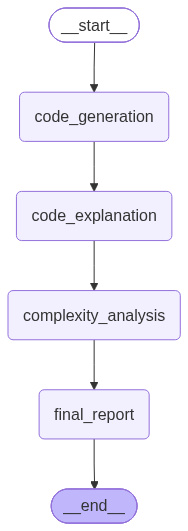

In [16]:
graph = StateGraph(ProgrammingState)

graph.add_node(code_generation)
graph.add_node(code_explanation)
graph.add_node(complexity_analysis)
graph.add_node(final_report)

#edges 

graph.add_edge(START,"code_generation")
graph.add_edge("code_generation","code_explanation")
graph.add_edge("code_explanation","complexity_analysis")
graph.add_edge("complexity_analysis","final_report")
graph.add_edge("final_report",END)


graph = graph.compile()
graph

In [17]:
initial_state = {
    "user_requests":"""Write binary search code. Assume you have a sorted data set and a target
    element. Return found index for the successful search, otherwise return -1""",
    "programming_language":"java"
}

In [18]:
result = graph.invoke(initial_state)
#print(result)
print(result["code_generation"])
print("\n\n")
print(result["code_explanation"])

# %%
print(result["final_report"])

```java
public class BinarySearch {

    /**
     * Performs binary search on a sorted array.
     *
     * @param sortedArray the array must be sorted in ascending order
     * @param target      the element to search for
     * @return the index of the target if found; otherwise -1
     */
    public static int binarySearch(int[] sortedArray, int target) {
        int left = 0;
        int right = sortedArray.length - 1;

        while (left <= right) {
            int mid = left + (right - left) / 2; // avoid overflow

            if (sortedArray[mid] == target) {
                return mid;
            } else if (sortedArray[mid] < target) {
                left = mid + 1;
            } else {
                right = mid - 1;
            }
        }

        return -1; // not found
    }

    // Example usage (optional)
    public static void main(String[] args) {
        int[] data = {1, 3, 5, 7, 9, 11, 13, 15};
        int target = 7;
        int index = binarySearch(data, target

# archive

In [13]:
## invoke the graph
user_query = {
    "messages":[
        HumanMessage(content="What is AI? Please answer in bullet form.")
    ]
}

response = graph.invoke(user_query)

# print(response["messages"][-1].content)
for m in response["messages"]:
     m.pretty_print()

================================ Human Message =================================

What is AI? Please answer in bullet form.
================================== Ai Message ==================================

- **Artificial Intelligence (AI)** is the field of computer science focused on creating systems that can perform tasks that normally require human intelligence.  
- **Core capabilities** include learning, reasoning, problem‑solving, perception, language understanding, and decision‑making.  
- **Types of AI**  
  - *Narrow (or weak) AI*: Designed for a specific task (e.g., image recognition, chatbots).  
  - *General (or strong) AI*: Hypothetical systems that can understand, learn, and apply knowledge across any domain like a human.  
- **Key techniques**  
  - *Machine Learning*: Algorithms that improve performance from data (e.g., supervised, unsupervised, reinforcement learning).  
  - *Deep Learning*: Neural networks with many layers that excel at complex pattern recognition (e.g.

In [8]:
llm_node(user_query)

{'messages': [AIMessage(content='- **Artificial Intelligence (AI)**: The field of computer science focused on creating systems that can perform tasks that normally require human intelligence.  \n- **Core capabilities**:  \n  - Learning from data (machine learning)  \n  - Reasoning and problem‑solving  \n  - Perceiving the world (computer vision, speech/audio processing)  \n  - Understanding and generating natural language (NLP)  \n  - Planning and decision‑making under uncertainty  \n- **Main approaches**:  \n  - **Rule‑based systems** – explicit logical rules programmed by humans  \n  - **Machine learning** – algorithms that improve performance from experience, especially deep learning with neural networks  \n  - **Hybrid systems** – combine rules, learning, and statistical methods  \n- **Common categories**:  \n  - **Narrow (or weak) AI** – specialized for a single task (e.g., image classification, recommendation engines)  \n  - **General (or strong) AI** – hypothetical systems with 

In [17]:
user_query = {
    "messages":[
        HumanMessage(content="give a dad joke/pun in malay")
    ]
}

In [18]:

#call the graph
try:
    response = graph.invoke(user_query)
except Exception as e:
    print(f"Error.{e}")
    
print(response)

{'messages': [HumanMessage(content='give a dad joke/pun in malay', additional_kwargs={}, response_metadata={}, id='5772747a-ba80-41c3-96bb-922d63b17643'), AIMessage(content='**Joke:**  \nKenapa durian tak pernah dapat kerja?  \n\nKerana dia selalu “bonggol” bila temuduga!  \n\n*(Bonggol = “bongkar”/“bongkar” dalam konteks kerja, tapi juga maksudnya durian yang berbonggol‑bonggol.)*  ', additional_kwargs={'reasoning_content': 'We need to respond with a dad joke/pun in Malay. Should be appropriate, friendly. Provide a joke. Probably include translation? Not required but could be helpful. Ensure it\'s a dad joke style: punny, maybe about "kucing" or "pisang". Let\'s produce one.'}, response_metadata={'token_usage': {'completion_tokens': 138, 'prompt_tokens': 90, 'total_tokens': 228, 'completion_time': 0.289634265, 'completion_tokens_details': {'reasoning_tokens': 60}, 'prompt_time': 0.004000102, 'prompt_tokens_details': None, 'queue_time': 0.168262951, 'total_time': 0.293634367}, 'model_n

In [19]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

give a dad joke/pun in malay
================================== Ai Message ==================================

**Joke:**  
Kenapa durian tak pernah dapat kerja?  

Kerana dia selalu “bonggol” bila temuduga!  

*(Bonggol = “bongkar”/“bongkar” dalam konteks kerja, tapi juga maksudnya durian yang berbonggol‑bonggol.)*
